# Laugh vs Choke — RNN BiLSTM Feature-Group Importance Experiment

            The model is trained **six times** with seeds 42–47. The RNN is not a
multi-branch network: it processes all channels as one temporal
sequence. Therefore, the experiment measures **feature-group reliance**
rather than architectural branch reliance. After every training run,
each normalized feature group is replaced by its training-set mean in
turn and the paired test-score drop is recorded.

            ## Experimental principle

            - The source-level train/validation/test split is loaded from the
              preprocessing manifest and never regenerated here.
            - Validation loss selects the best epoch; the test set is not used
              for training or early stopping.
            - Six fixed seeds measure variation caused by initialization and
              mini-batch order.
            - Ablation uses **mean masking**: after z-score normalization, the
              selected channels are set to zero, which represents their
              training-set mean.
            - Importance is a paired difference:

              \[
              I_{g,m} = m_{\mathrm{full}} - m_{\mathrm{without}\ g}
              \]

              A positive value means performance decreased when group \(g\) was
              masked. A negative value means that metric improved when the group
              was masked.

            This is a model-reliance experiment. It measures how the trained
            model uses each group; it does not prove that every individual
            feature inside the group is independently important.

## 1. Imports

In [11]:
import gc
import json
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

sns.set_theme(style="whitegrid")

## 2. Paths, metadata, and experiment settings

In [13]:
# Mount Google Drive when running in Colab.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab; using the configured local paths.")


# Change only this path if the project folder moves.
PROJECT_DIR = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")

# Both layouts have been used by versions of the preprocessing program.
PROCESSED_DIR = PROJECT_DIR / "processed"
if not PROCESSED_DIR.exists() and (PROJECT_DIR / "data" / "processed").exists():
    PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

META_PATH = PROCESSED_DIR / "meta.json"
NORM_PATH = PROCESSED_DIR / "norm_stats.json"
MANIFEST_PATH = PROCESSED_DIR / "manifest.json"

for required_path in (META_PATH, NORM_PATH, MANIFEST_PATH):
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required preprocessing output not found: {required_path}\n"
            "Check PROJECT_DIR and run the preprocessing notebook/script first."
        )

with open(META_PATH, "r", encoding="utf-8") as f:
    meta = json.load(f)
with open(NORM_PATH, "r", encoding="utf-8") as f:
    norm_stats = json.load(f)
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

CHANNEL_NAMES = list(meta["channels"])
N_CHANNELS = int(meta["n_channels"])
HEIGHT, WIDTH = int(meta["tensor_shape"][1]), int(meta["tensor_shape"][2])

CLASS_NAMES = ["choking", "laughter"]
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}

# Six independent repetitions for each architecture.
SEEDS = [42, 43, 44, 45, 46, 47]

BATCH_SIZE = 32
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-3
NUM_EPOCHS = 15
EARLY_STOPPING_PATIENCE = 8
SCHEDULER_PATIENCE = 4
SCHEDULER_FACTOR = 0.5
GRAD_CLIP = 5.0

RESULTS_DIR = PROJECT_DIR / "branch_importance_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Processed directory:", PROCESSED_DIR)
print("Device:", device)
print("Input shape:", (N_CHANNELS, HEIGHT, WIDTH))
print("Channels:", CHANNEL_NAMES)
print("Seeds:", SEEDS)

Mounted at /content/drive
Processed directory: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/processed
Device: cuda
Input shape: (20, 128, 128)
Channels: ['log_mel', 'harmonic_mel', 'percussive_mel', 'delta', 'delta_delta', 'zcr', 'rms', 'spectral_centroid', 'spectral_rolloff', 'spectral_bandwidth', 'spectral_contrast', 'chroma', 'mfcc', 'tonnetz', 'spectral_flatness', 'f0', 'voiced_prob', 'spectral_flux', 'wide_band_mel', 'rms_periodicity']
Seeds: [42, 43, 44, 45, 46, 47]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

## 3. Feature-group definitions

In [14]:
# These are the same three groups used by the multi-fusion CNN.
FEATURE_GROUPS = {
    "Tonal": [
        "log_mel", "harmonic_mel", "chroma", "mfcc",
        "tonnetz", "f0", "voiced_prob",
    ],
    "Transient": [
        "percussive_mel", "delta", "delta_delta",
        "spectral_flux", "wide_band_mel",
    ],
    "Energy/Noise": [
        "zcr", "rms", "spectral_centroid", "spectral_rolloff",
        "spectral_bandwidth", "spectral_contrast",
        "spectral_flatness", "rms_periodicity",
    ],
}

GROUP_INDICES = {
    group: [CHANNEL_NAMES.index(name) for name in names]
    for group, names in FEATURE_GROUPS.items()
}

# Fail immediately if preprocessing channel names no longer match the experiment.
grouped_names = [name for names in FEATURE_GROUPS.values() for name in names]
missing = sorted(set(grouped_names) - set(CHANNEL_NAMES))
ungrouped = sorted(set(CHANNEL_NAMES) - set(grouped_names))
duplicates = sorted({name for name in grouped_names if grouped_names.count(name) > 1})

if missing or ungrouped or duplicates:
    raise ValueError(
        "Feature-group definition does not match meta.json.\n"
        f"Missing from tensor: {missing}\n"
        f"Ungrouped tensor channels: {ungrouped}\n"
        f"Duplicated group entries: {duplicates}"
    )

group_table = pd.DataFrame(
    [
        {
            "Group": group,
            "Number of channels": len(names),
            "Channels": ", ".join(names),
        }
        for group, names in FEATURE_GROUPS.items()
    ]
)
display(group_table)

,Group,Number of channels,Channels
0,Tonal,7,"log_mel, harmonic_mel, chroma, mfcc, tonnetz, ..."
1,Transient,5,"percussive_mel, delta, delta_delta, spectral_f..."
2,Energy/Noise,8,"zcr, rms, spectral_centroid, spectral_rolloff,..."


## 4. Dataset and deterministic data loaders

In [15]:
def collect_split_samples(split_name):
    split_dir = PROCESSED_DIR / split_name
    samples = []
    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        label = class_to_idx[class_name]
        for file_path in sorted(class_dir.glob("*.npy")):
            samples.append((file_path, label))
    if not samples:
        raise RuntimeError(f"No .npy tensors found in {split_dir}")
    return samples


train_samples = collect_split_samples("train")
val_samples = collect_split_samples("val")
test_samples = collect_split_samples("test")


class AudioFeatureDataset(Dataset):
    """Loads tensors and applies train-statistics z-score normalization."""

    def __init__(self, samples, stats):
        self.samples = samples
        self.mean = np.asarray(stats["mean"], dtype=np.float32)[:, None, None]
        self.std = np.asarray(stats["std"], dtype=np.float32)[:, None, None]
        self.std = np.maximum(self.std, 1e-8)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]
        x = np.load(file_path).astype(np.float32)
        if x.shape != (N_CHANNELS, HEIGHT, WIDTH):
            raise ValueError(
                f"{file_path} has shape {x.shape}; "
                f"expected {(N_CHANNELS, HEIGHT, WIDTH)}"
            )
        x = (x - self.mean) / self.std
        return torch.from_numpy(x), torch.tensor(label, dtype=torch.long)


train_dataset = AudioFeatureDataset(train_samples, norm_stats)
val_dataset = AudioFeatureDataset(val_samples, norm_stats)
test_dataset = AudioFeatureDataset(test_samples, norm_stats)


def make_loaders(seed):
    """A seeded generator makes the training shuffle reproducible per run."""
    generator = torch.Generator()
    generator.manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    return train_loader, val_loader, test_loader


def split_counts(samples):
    counts = Counter(label for _, label in samples)
    return {CLASS_NAMES[i]: counts.get(i, 0) for i in range(NUM_CLASSES)}


split_summary = pd.DataFrame(
    {
        "Train tensors": split_counts(train_samples),
        "Validation tensors": split_counts(val_samples),
        "Test tensors": split_counts(test_samples),
    }
)
display(split_summary)

# Loss weights depend only on the training split.
train_counts = Counter(label for _, label in train_samples)
count_tensor = torch.tensor(
    [train_counts.get(i, 0) for i in range(NUM_CLASSES)],
    dtype=torch.float32,
)
class_weights = count_tensor.sum() / (NUM_CLASSES * count_tensor.clamp(min=1))
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

print(
    "Class weights:",
    {CLASS_NAMES[i]: round(float(class_weights[i]), 4) for i in range(NUM_CLASSES)},
)

,Train tensors,Validation tensors,Test tensors
choking,352,34,34
laughter,288,46,25


Class weights: {'choking': 0.9091, 'laughter': 1.1111}


## 5. Model

In [16]:
class AudioBiLSTM(nn.Module):
    """
    BiLSTM over the time axis of the complete feature tensor.

    Unlike the CNN, this model has no separate architectural branches.
    Its ablation therefore measures reliance on the same three feature groups
    by replacing a group's normalized channels with their training mean.
    """

    def __init__(
        self,
        n_channels,
        height,
        num_classes=2,
        embed_dim=64,
        hidden_size=64,
        num_layers=1,
        dropout=0.3,
        freq_pool=False,
    ):
        super().__init__()
        self.freq_pool = freq_pool
        self.input_dim = n_channels if freq_pool else n_channels * height

        self.frame_norm = nn.LayerNorm(self.input_dim)
        self.frame_embed = nn.Sequential(
            nn.Linear(self.input_dim, embed_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes),
        )

    def forward(self, x, masked_group=None):
        if masked_group is not None:
            x = x.clone()
            x[:, GROUP_INDICES[masked_group], :, :] = 0.0

        batch, channels, height, frames = x.shape
        if self.freq_pool:
            x = x.mean(dim=2).permute(0, 2, 1)
        else:
            x = x.permute(0, 3, 1, 2).reshape(
                batch, frames, channels * height
            )

        x = self.frame_norm(x)
        x = self.frame_embed(x)
        sequence, _ = self.lstm(x)
        pooled = sequence.mean(dim=1)
        return self.classifier(pooled)


# Keep this identical in all six RNN repetitions.
USE_FREQ_POOL = False

ARCHITECTURE_NAME = "RNN BiLSTM"
ARCHITECTURE_SLUG = "rnn_bilstm"
RAW_RESULTS_FILENAME = "rnn_bilstm_ablation_runs.csv"


def build_model():
    return AudioBiLSTM(
        n_channels=N_CHANNELS,
        height=HEIGHT,
        num_classes=NUM_CLASSES,
        embed_dim=64,
        hidden_size=64,
        num_layers=1,
        dropout=0.3,
        freq_pool=USE_FREQ_POOL,
    )


parameter_check_model = build_model()
trainable_parameters = sum(
    parameter.numel()
    for parameter in parameter_check_model.parameters()
    if parameter.requires_grad
)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Frequency pooling:", USE_FREQ_POOL)
del parameter_check_model

Trainable parameters: 241,874
Frequency pooling: False


## 6. Shared training and evaluation utilities

In [17]:
def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except TypeError:
        # Compatibility with older PyTorch versions.
        torch.use_deterministic_algorithms(True)


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, masked_group=None):
    model.eval()
    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        logits = model(x, masked_group=masked_group)
        loss = criterion(logits, y)

        total_loss += loss.item() * y.size(0)
        all_labels.extend(y.cpu().numpy().tolist())
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())

    return (
        total_loss / len(all_labels),
        np.asarray(all_labels),
        np.asarray(all_predictions),
    )


def load_weights_compatibly(model, checkpoint_path):
    try:
        state = torch.load(checkpoint_path, map_location=device, weights_only=True)
    except TypeError:
        state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state)


def train_model(model, seed, checkpoint_path):
    train_loader, val_loader, test_loader = make_loaders(seed)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        patience=SCHEDULER_PATIENCE,
        factor=SCHEDULER_FACTOR,
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_labels, val_predictions = evaluate(model, val_loader)
        val_accuracy = accuracy_score(val_labels, val_predictions)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]
        print(
            f"  Epoch {epoch:02d}/{NUM_EPOCHS} | "
            f"train loss {train_loss:.4f} | train acc {train_accuracy:.4f} | "
            f"val loss {val_loss:.4f} | val acc {val_accuracy:.4f} | "
            f"lr {current_lr:.6f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
                print(f"  Early stopping after epoch {epoch}.")
                break

    load_weights_compatibly(model, checkpoint_path)
    return history, best_epoch, best_val_loss, test_loader


def calculate_metrics(labels, predictions):
    precision, recall, f1, support = precision_recall_fscore_support(
        labels,
        predictions,
        labels=list(range(NUM_CLASSES)),
        zero_division=0,
    )
    result = {
        "accuracy": accuracy_score(labels, predictions),
    }
    for index, class_name in enumerate(CLASS_NAMES):
        result[f"{class_name}_precision"] = precision[index]
        result[f"{class_name}_recall"] = recall[index]
        result[f"{class_name}_f1"] = f1[index]
        result[f"{class_name}_support"] = int(support[index])
    result["macro_f1"] = float(np.mean(f1))
    return result

## 7. Run the six experiments

This is the time-consuming cell. It trains six complete models and
saves the best validation-loss checkpoint for each seed. Every
checkpoint is evaluated four ways: full input, without Tonal,
without Transient, and without Energy/Noise.

In [18]:
CONDITIONS = {
    "Full model": None,
    "Without Tonal": "Tonal",
    "Without Transient": "Transient",
    "Without Energy/Noise": "Energy/Noise",
}

CHECKPOINT_DIR = RESULTS_DIR / ARCHITECTURE_SLUG / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

all_results = []
all_histories = {}

for run_number, seed in enumerate(SEEDS, start=1):
    print("\n" + "=" * 76)
    print(f"{ARCHITECTURE_NAME} — run {run_number}/{len(SEEDS)}, seed={seed}")
    print("=" * 76)

    set_global_seed(seed)
    model = build_model().to(device)
    checkpoint_path = CHECKPOINT_DIR / f"{ARCHITECTURE_SLUG}_seed_{seed}.pth"

    history, best_epoch, best_val_loss, test_loader = train_model(
        model=model,
        seed=seed,
        checkpoint_path=checkpoint_path,
    )
    all_histories[str(seed)] = history

    for condition, masked_group in CONDITIONS.items():
        test_loss, labels, predictions = evaluate(
            model,
            test_loader,
            masked_group=masked_group,
        )
        row = {
            "architecture": ARCHITECTURE_NAME,
            "run": run_number,
            "seed": seed,
            "condition": condition,
            "masked_group": masked_group or "None",
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "test_loss": test_loss,
        }
        row.update(calculate_metrics(labels, predictions))
        all_results.append(row)

    run_preview = pd.DataFrame(all_results)
    run_preview = run_preview[run_preview["seed"] == seed][
        [
            "condition",
            "accuracy",
            "choking_precision",
            "choking_recall",
            "choking_f1",
            "laughter_precision",
            "laughter_recall",
            "laughter_f1",
        ]
    ]
    display(run_preview.round(4))

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(all_results)

RAW_RESULTS_PATH = RESULTS_DIR / RAW_RESULTS_FILENAME
HISTORY_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_training_histories.json"
results_df.to_csv(RAW_RESULTS_PATH, index=False)
with open(HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(all_histories, f, indent=2)

print("\nSaved raw results to:", RAW_RESULTS_PATH)
print("Saved training histories to:", HISTORY_PATH)


RNN BiLSTM — run 1/6, seed=42
  Epoch 01/15 | train loss 0.6345 | train acc 0.6859 | val loss 0.5280 | val acc 0.8000 | lr 0.000500
  Epoch 02/15 | train loss 0.4410 | train acc 0.8438 | val loss 0.3312 | val acc 0.8500 | lr 0.000500
  Epoch 03/15 | train loss 0.2500 | train acc 0.9187 | val loss 0.2149 | val acc 0.9250 | lr 0.000500
  Epoch 04/15 | train loss 0.1376 | train acc 0.9516 | val loss 0.3495 | val acc 0.8375 | lr 0.000500
  Epoch 05/15 | train loss 0.1013 | train acc 0.9688 | val loss 0.3663 | val acc 0.8750 | lr 0.000500
  Epoch 06/15 | train loss 0.0638 | train acc 0.9828 | val loss 0.2722 | val acc 0.9000 | lr 0.000500
  Epoch 07/15 | train loss 0.0343 | train acc 0.9906 | val loss 0.2414 | val acc 0.8875 | lr 0.000500
  Epoch 08/15 | train loss 0.0483 | train acc 0.9812 | val loss 0.1967 | val acc 0.8875 | lr 0.000500
  Epoch 09/15 | train loss 0.0340 | train acc 0.9922 | val loss 0.1915 | val acc 0.9125 | lr 0.000500
  Epoch 10/15 | train loss 0.0206 | train acc 0.995

,condition,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
0,Full model,0.9153,1.0000,0.8529,0.9206,0.8333,1.00,0.9091
1,Without Tonal,0.8305,0.8000,0.9412,0.8649,0.8947,0.68,0.7727
2,Without Transient,0.7797,0.7234,1.0000,0.8395,1.0000,0.48,0.6486
3,Without Energy/Noise,0.6610,1.0000,0.4118,0.5833,0.5556,1.00,0.7143



RNN BiLSTM — run 2/6, seed=43
  Epoch 01/15 | train loss 0.6278 | train acc 0.7141 | val loss 0.5270 | val acc 0.8375 | lr 0.000500
  Epoch 02/15 | train loss 0.4063 | train acc 0.8719 | val loss 0.2859 | val acc 0.8625 | lr 0.000500
  Epoch 03/15 | train loss 0.2416 | train acc 0.9203 | val loss 0.3321 | val acc 0.8250 | lr 0.000500
  Epoch 04/15 | train loss 0.1567 | train acc 0.9437 | val loss 0.5600 | val acc 0.8250 | lr 0.000500
  Epoch 05/15 | train loss 0.0905 | train acc 0.9672 | val loss 0.1676 | val acc 0.9500 | lr 0.000500
  Epoch 06/15 | train loss 0.0550 | train acc 0.9812 | val loss 0.6407 | val acc 0.8500 | lr 0.000500
  Epoch 07/15 | train loss 0.0691 | train acc 0.9781 | val loss 0.7985 | val acc 0.8250 | lr 0.000500
  Epoch 08/15 | train loss 0.0334 | train acc 0.9859 | val loss 0.3284 | val acc 0.8875 | lr 0.000500
  Epoch 09/15 | train loss 0.0161 | train acc 0.9969 | val loss 0.4390 | val acc 0.8875 | lr 0.000500
  Epoch 10/15 | train loss 0.0154 | train acc 0.996

,condition,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
4,Full model,0.8983,1.0000,0.8235,0.9032,0.8065,1.00,0.8929
5,Without Tonal,0.8136,0.9259,0.7353,0.8197,0.7188,0.92,0.8070
6,Without Transient,0.8305,0.7857,0.9706,0.8684,0.9412,0.64,0.7619
7,Without Energy/Noise,0.6102,0.8667,0.3824,0.5306,0.5227,0.92,0.6667



RNN BiLSTM — run 3/6, seed=44
  Epoch 01/15 | train loss 0.6481 | train acc 0.6672 | val loss 0.5445 | val acc 0.7875 | lr 0.000500
  Epoch 02/15 | train loss 0.4696 | train acc 0.8547 | val loss 0.3403 | val acc 0.8500 | lr 0.000500
  Epoch 03/15 | train loss 0.2796 | train acc 0.8969 | val loss 0.2457 | val acc 0.8875 | lr 0.000500
  Epoch 04/15 | train loss 0.1630 | train acc 0.9391 | val loss 0.7366 | val acc 0.7500 | lr 0.000500
  Epoch 05/15 | train loss 0.1260 | train acc 0.9531 | val loss 0.3842 | val acc 0.8500 | lr 0.000500
  Epoch 06/15 | train loss 0.0816 | train acc 0.9750 | val loss 0.2361 | val acc 0.8750 | lr 0.000500
  Epoch 07/15 | train loss 0.0397 | train acc 0.9938 | val loss 0.6029 | val acc 0.8125 | lr 0.000500
  Epoch 08/15 | train loss 0.0230 | train acc 0.9938 | val loss 0.4114 | val acc 0.8625 | lr 0.000500
  Epoch 09/15 | train loss 0.0200 | train acc 0.9953 | val loss 0.7712 | val acc 0.7875 | lr 0.000500
  Epoch 10/15 | train loss 0.0138 | train acc 0.996

...


RNN BiLSTM — run 5/6, seed=46
  Epoch 01/15 | train loss 0.6281 | train acc 0.6312 | val loss 0.5003 | val acc 0.8375 | lr 0.000500
  Epoch 02/15 | train loss 0.4318 | train acc 0.8562 | val loss 0.3319 | val acc 0.8125 | lr 0.000500
  Epoch 03/15 | train loss 0.2363 | train acc 0.9203 | val loss 0.3198 | val acc 0.8125 | lr 0.000500
  Epoch 04/15 | train loss 0.1413 | train acc 0.9594 | val loss 0.4850 | val acc 0.8750 | lr 0.000500
  Epoch 05/15 | train loss 0.1182 | train acc 0.9547 | val loss 0.3345 | val acc 0.8500 | lr 0.000500
  Epoch 06/15 | train loss 0.0975 | train acc 0.9719 | val loss 0.1902 | val acc 0.9375 | lr 0.000500
  Epoch 07/15 | train loss 0.0436 | train acc 0.9875 | val loss 0.4830 | val acc 0.8875 | lr 0.000500
  Epoch 08/15 | train loss 0.0642 | train acc 0.9781 | val loss 0.6181 | val acc 0.8500 | lr 0.000500
  Epoch 09/15 | train loss 0.0448 | train acc 0.9891 | val loss 0.1768 | val acc 0.9125 | lr 0.000500
  Epoch 10/15 | train loss 0.0200 | train acc 0.998

,condition,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
16,Full model,0.8814,0.9655,0.8235,0.8889,0.8000,0.96,0.8727
17,Without Tonal,0.7119,0.8148,0.6471,0.7213,0.6250,0.80,0.7018
18,Without Transient,0.7966,0.7500,0.9706,0.8462,0.9333,0.56,0.7000
19,Without Energy/Noise,0.6441,1.0000,0.3824,0.5532,0.5435,1.00,0.7042



RNN BiLSTM — run 6/6, seed=47
  Epoch 01/15 | train loss 0.6261 | train acc 0.7156 | val loss 0.5237 | val acc 0.8125 | lr 0.000500
  Epoch 02/15 | train loss 0.4261 | train acc 0.8469 | val loss 0.3079 | val acc 0.8625 | lr 0.000500
  Epoch 03/15 | train loss 0.2442 | train acc 0.9187 | val loss 0.2754 | val acc 0.8750 | lr 0.000500
  Epoch 04/15 | train loss 0.1501 | train acc 0.9453 | val loss 0.4979 | val acc 0.8125 | lr 0.000500
  Epoch 05/15 | train loss 0.1010 | train acc 0.9703 | val loss 0.7078 | val acc 0.8000 | lr 0.000500
  Epoch 06/15 | train loss 0.0754 | train acc 0.9750 | val loss 0.4988 | val acc 0.8625 | lr 0.000500
  Epoch 07/15 | train loss 0.0444 | train acc 0.9922 | val loss 0.2815 | val acc 0.9000 | lr 0.000500
  Epoch 08/15 | train loss 0.0219 | train acc 0.9938 | val loss 0.7009 | val acc 0.8375 | lr 0.000250
  Epoch 09/15 | train loss 0.0166 | train acc 0.9984 | val loss 0.2822 | val acc 0.9250 | lr 0.000250
  Epoch 10/15 | train loss 0.0121 | train acc 0.998

,condition,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
20,Full model,0.9322,0.9688,0.9118,0.9394,0.8889,0.96,0.9231
21,Without Tonal,0.8136,0.8710,0.7941,0.8308,0.7500,0.84,0.7925
22,Without Transient,0.7966,0.7391,1.0000,0.8500,1.0000,0.52,0.6842
23,Without Energy/Noise,0.6102,0.9231,0.3529,0.5106,0.5217,0.96,0.6761



Saved raw results to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_ablation_runs.csv
Saved training histories to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_training_histories.json


## 8. Tables and branch/group ranking

In [19]:
METRIC_COLUMNS = [
    "accuracy",
    "choking_precision",
    "choking_recall",
    "choking_f1",
    "laughter_precision",
    "laughter_recall",
    "laughter_f1",
]

condition_order = list(CONDITIONS.keys())


def mean_std_text(series):
    return f"{series.mean():.4f} ± {series.std(ddof=1):.4f}"


# Table 1: mean ± standard deviation for every requested test metric.
performance_table = (
    results_df.groupby("condition", sort=False)[METRIC_COLUMNS]
    .agg(mean_std_text)
    .reindex(condition_order)
)
performance_table.index.name = "Evaluation condition"
display(performance_table)

PERFORMANCE_TABLE_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_performance_mean_std.csv"
performance_table.to_csv(PERFORMANCE_TABLE_PATH)


# Paired importance: full-model score minus the ablated score for the SAME seed.
# Positive drop = the group helped. Negative drop = the model improved without it.
full_by_seed = (
    results_df[results_df["condition"] == "Full model"]
    .set_index("seed")
)

importance_rows = []
for _, ablated_row in results_df[results_df["condition"] != "Full model"].iterrows():
    seed = int(ablated_row["seed"])
    full_row = full_by_seed.loc[seed]
    importance_row = {
        "architecture": ARCHITECTURE_NAME,
        "run": int(ablated_row["run"]),
        "seed": seed,
        "group": ablated_row["masked_group"],
    }
    for metric in METRIC_COLUMNS:
        importance_row[f"drop_{metric}"] = (
            float(full_row[metric]) - float(ablated_row[metric])
        )

    # A compact ranking score. Detailed metric drops remain the primary evidence.
    importance_row["composite_drop"] = np.mean(
        [
            importance_row["drop_accuracy"],
            importance_row["drop_choking_f1"],
            importance_row["drop_laughter_f1"],
        ]
    )
    importance_rows.append(importance_row)

importance_df = pd.DataFrame(importance_rows)
IMPORTANCE_RAW_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_paired_importance_runs.csv"
importance_df.to_csv(IMPORTANCE_RAW_PATH, index=False)

drop_columns = [f"drop_{metric}" for metric in METRIC_COLUMNS] + ["composite_drop"]
importance_summary = (
    importance_df.groupby("group", sort=False)[drop_columns]
    .agg(["mean", "std"])
)
importance_summary.columns = [
    f"{metric}_{stat}" for metric, stat in importance_summary.columns
]
importance_summary["positive_composite_runs"] = (
    importance_df.assign(positive=importance_df["composite_drop"] > 0)
    .groupby("group", sort=False)["positive"]
    .sum()
)
importance_summary = importance_summary.sort_values(
    "composite_drop_mean",
    ascending=False,
)
importance_summary.insert(
    0,
    "importance_rank",
    np.arange(1, len(importance_summary) + 1),
)

IMPORTANCE_SUMMARY_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_importance_summary.csv"
importance_summary.to_csv(IMPORTANCE_SUMMARY_PATH)

importance_display_columns = [
    "importance_rank",
    "drop_accuracy_mean",
    "drop_choking_precision_mean",
    "drop_choking_recall_mean",
    "drop_choking_f1_mean",
    "drop_laughter_precision_mean",
    "drop_laughter_recall_mean",
    "drop_laughter_f1_mean",
    "composite_drop_mean",
    "composite_drop_std",
    "positive_composite_runs",
]
print(
    "Branch/group importance: mean paired score drop after masking.\n"
    "Positive values indicate useful information; negative values indicate that "
    "the metric improved when the group was masked."
)
display(importance_summary[importance_display_columns].round(4))

print("\nSaved:", PERFORMANCE_TABLE_PATH)
print("Saved:", IMPORTANCE_RAW_PATH)
print("Saved:", IMPORTANCE_SUMMARY_PATH)

,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
Evaluation condition,,,,,,,
Full model,0.8842 ± 0.0421,0.9734 ± 0.0366,0.8235 ± 0.0789,0.8897 ± 0.0460,0.8063 ± 0.0635,0.9667 ± 0.0468,0.8773 ± 0.0391
Without Tonal,0.7994 ± 0.0447,0.8712 ± 0.0786,0.7794 ± 0.1272,0.8139 ± 0.0539,0.7536 ± 0.1044,0.8267 ± 0.1204,0.7772 ± 0.0393
Without Transient,0.7966 ± 0.0322,0.7463 ± 0.0359,0.9853 ± 0.0161,0.8486 ± 0.0186,0.9693 ± 0.0338,0.5400 ± 0.0938,0.6880 ± 0.0724
Without Energy/Noise,0.6356 ± 0.0234,0.9337 ± 0.0581,0.3971 ± 0.0308,0.5563 ± 0.0329,0.5394 ± 0.0157,0.9600 ± 0.0358,0.6906 ± 0.0198


Branch/group importance: mean paired score drop after masking.
Positive values indicate useful information; negative values indicate that the metric improved when the group was masked.


,importance_rank,drop_accuracy_mean,drop_choking_precision_mean,drop_choking_recall_mean,drop_choking_f1_mean,drop_laughter_precision_mean,drop_laughter_recall_mean,drop_laughter_f1_mean,composite_drop_mean,composite_drop_std,positive_composite_runs
group,,,,,,,,,,,
Energy/Noise,1,0.2486,0.0397,0.4265,0.3334,0.2669,0.0067,0.1867,0.2562,0.0529,6
Transient,2,0.0876,0.2271,-0.1618,0.0410,-0.1630,0.4267,0.1892,0.1059,0.0644,5
Tonal,3,0.0847,0.1022,0.0441,0.0758,0.0528,0.1400,0.1001,0.0869,0.0550,6



Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_performance_mean_std.csv
Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_paired_importance_runs.csv
Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_importance_summary.csv


## 9. Performance and importance graphs

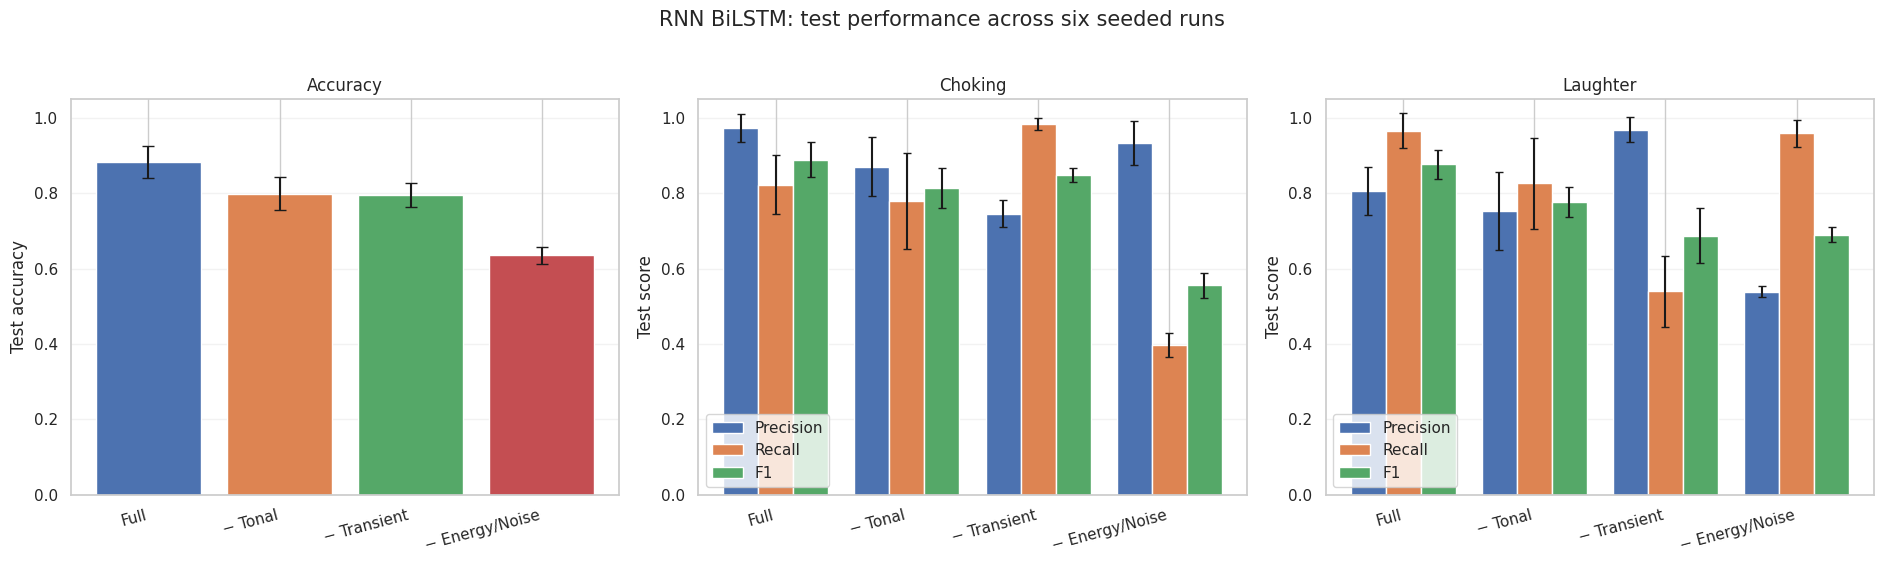

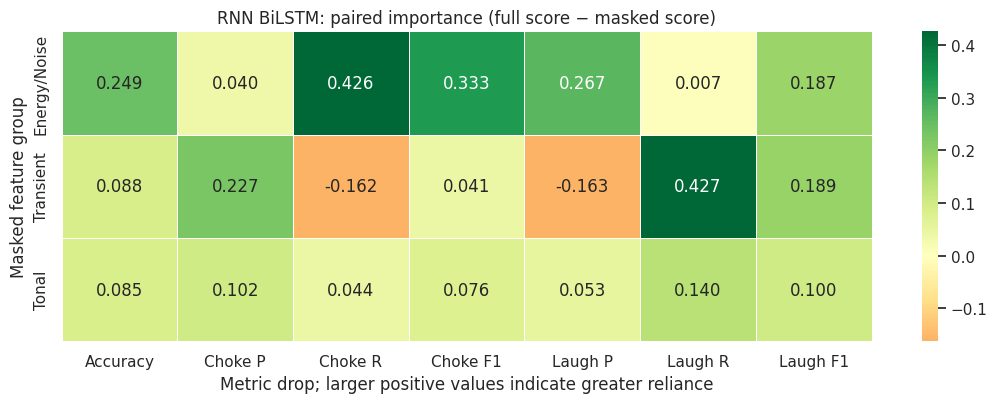

Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_performance.png
Saved: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results/rnn_bilstm_importance_heatmap.png


In [20]:
condition_colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]


def grouped_metric_plot(ax, metrics, title):
    means = (
        results_df.groupby("condition", sort=False)[metrics]
        .mean()
        .reindex(condition_order)
    )
    stds = (
        results_df.groupby("condition", sort=False)[metrics]
        .std(ddof=1)
        .reindex(condition_order)
    )
    x = np.arange(len(condition_order))
    width = 0.8 / len(metrics)
    for metric_index, metric in enumerate(metrics):
        offset = (metric_index - (len(metrics) - 1) / 2) * width
        label = metric.split("_")[-1].replace("f1", "F1").title()
        ax.bar(
            x + offset,
            means[metric],
            width,
            yerr=stds[metric],
            capsize=3,
            label=label,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(
        ["Full", "− Tonal", "− Transient", "− Energy/Noise"],
        rotation=15,
        ha="right",
    )
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Test score")
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)


fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

accuracy_mean = (
    results_df.groupby("condition", sort=False)["accuracy"]
    .mean()
    .reindex(condition_order)
)
accuracy_std = (
    results_df.groupby("condition", sort=False)["accuracy"]
    .std(ddof=1)
    .reindex(condition_order)
)
axes[0].bar(
    np.arange(len(condition_order)),
    accuracy_mean,
    yerr=accuracy_std,
    capsize=4,
    color=condition_colors,
)
axes[0].set_xticks(np.arange(len(condition_order)))
axes[0].set_xticklabels(
    ["Full", "− Tonal", "− Transient", "− Energy/Noise"],
    rotation=15,
    ha="right",
)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Accuracy")
axes[0].grid(axis="y", alpha=0.25)

grouped_metric_plot(
    axes[1],
    ["choking_precision", "choking_recall", "choking_f1"],
    "Choking",
)
grouped_metric_plot(
    axes[2],
    ["laughter_precision", "laughter_recall", "laughter_f1"],
    "Laughter",
)

fig.suptitle(
    f"{ARCHITECTURE_NAME}: test performance across six seeded runs",
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
PERFORMANCE_PLOT_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_performance.png"
plt.savefig(PERFORMANCE_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()


heatmap_columns = [
    "drop_accuracy",
    "drop_choking_precision",
    "drop_choking_recall",
    "drop_choking_f1",
    "drop_laughter_precision",
    "drop_laughter_recall",
    "drop_laughter_f1",
]
heatmap_labels = [
    "Accuracy",
    "Choke P",
    "Choke R",
    "Choke F1",
    "Laugh P",
    "Laugh R",
    "Laugh F1",
]
heatmap_data = (
    importance_df.groupby("group", sort=False)[heatmap_columns]
    .mean()
    .loc[importance_summary.index]
)

plt.figure(figsize=(11, 4.2))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    center=0,
    cmap="RdYlGn",
    xticklabels=heatmap_labels,
    yticklabels=heatmap_data.index,
    linewidths=0.5,
)
plt.title(
    f"{ARCHITECTURE_NAME}: paired importance (full score − masked score)"
)
plt.xlabel("Metric drop; larger positive values indicate greater reliance")
plt.ylabel("Masked feature group")
plt.tight_layout()
IMPORTANCE_PLOT_PATH = RESULTS_DIR / f"{ARCHITECTURE_SLUG}_importance_heatmap.png"
plt.savefig(IMPORTANCE_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", PERFORMANCE_PLOT_PATH)
print("Saved:", IMPORTANCE_PLOT_PATH)

## 10. Optional CNN–RNN comparison

Run both notebooks first. Each writes a standardized result table to
the same results folder. This cell combines them into final
architecture-comparison tables and figures.

,accuracy,choking_precision,choking_recall,choking_f1,laughter_precision,laughter_recall,laughter_f1
architecture,,,,,,,
CNN Multi-Fusion,0.8559 ± 0.0439,0.9105 ± 0.0494,0.8333 ± 0.0515,0.8694 ± 0.0406,0.7982 ± 0.0544,0.8867 ± 0.0641,0.8391 ± 0.0485
RNN BiLSTM,0.8842 ± 0.0421,0.9734 ± 0.0366,0.8235 ± 0.0789,0.8897 ± 0.0460,0.8063 ± 0.0635,0.9667 ± 0.0468,0.8773 ± 0.0391


drop_accuracy_mean  drop_accuracy_std  \
architecture     group                                                 
CNN Multi-Fusion Energy/Noise              0.3023             0.1058   
                 Tonal                     0.0311             0.0447   
                 Transient                 0.2712             0.0387   
RNN BiLSTM       Energy/Noise              0.2486             0.0510   
                 Tonal                     0.0847             0.0557   
                 Transient                 0.0876             0.0581   

                               drop_choking_precision_mean  \
architecture     group                                       
CNN Multi-Fusion Energy/Noise                       0.2665   
                 Tonal                              0.1020   
                 Transient                          0.3291   
RNN BiLSTM       Energy/Noise                       0.0397   
                 Tonal                              0.1022   
                 Transient                          0.2271   

                               drop_choking_precision_std  \
architecture     group                                      
CNN Multi-Fusion Energy/Noise                      0.3550   
                 Tonal                             0.0823   
                 Transient                         0.0508   
RNN BiLSTM       Energy/Noise                      0.0751   
                 Tonal                             0.0683   
                 Transient                         0.0250   

                               drop_choking_recall_mean  \
architecture     group                                    
CNN Multi-Fusion Energy/Noise                    0.3627   
                 Tonal                          -0.0980   
                 Transient                      -0.1667   
RNN BiLSTM       Energy/Noise                    0.4265   
                 Tonal                           0.0441   
                 Transient                      -0.1618   

                               drop_choking_recall_std  drop_choking_f1_mean  \
architecture     group                                                         
CNN Multi-Fusion Energy/Noise                   0.4555                0.4275   
                 Tonal                          0.1215                0.0090   
                 Transient                      0.0515                0.1341   
RNN BiLSTM       Energy/Noise                   0.0944                0.3334   
                 Tonal                          0.1032                0.0758   
                 Transient                      0.0690                0.0410   

                               drop_choking_f1_std  \
architecture     group                               
CNN Multi-Fusion Energy/Noise               0.3440   
                 Tonal                      0.0423   
                 Transient                  0.0365   
RNN BiLSTM       Energy/Noise               0.0650   
                 Tonal                      0.0571   
                 Transient                  0.0544   

                               drop_laughter_precision_mean  \
architecture     group                                        
CNN Multi-Fusion Energy/Noise                        0.2278   
                 Tonal                              -0.1091   
                 Transient                           0.6316   
RNN BiLSTM       Energy/Noise                        0.2669   
                 Tonal                               0.0528   
                 Transient                          -0.1630   

                               drop_laughter_precision_std  \
architecture     group                                       
CNN Multi-Fusion Energy/Noise                       0.1742   
                 Tonal                              0.1509   
                 Transient                          0.3700   
RNN BiLSTM       Energy/Noise                       0.0666   
                 Tonal                      

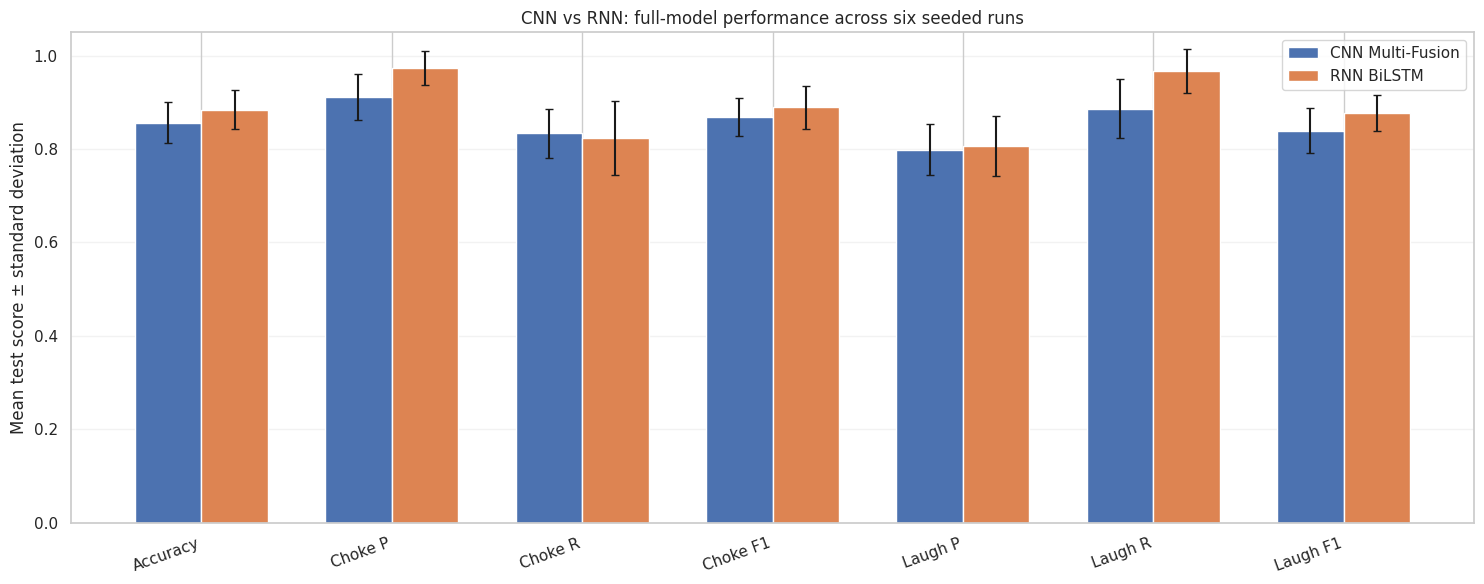

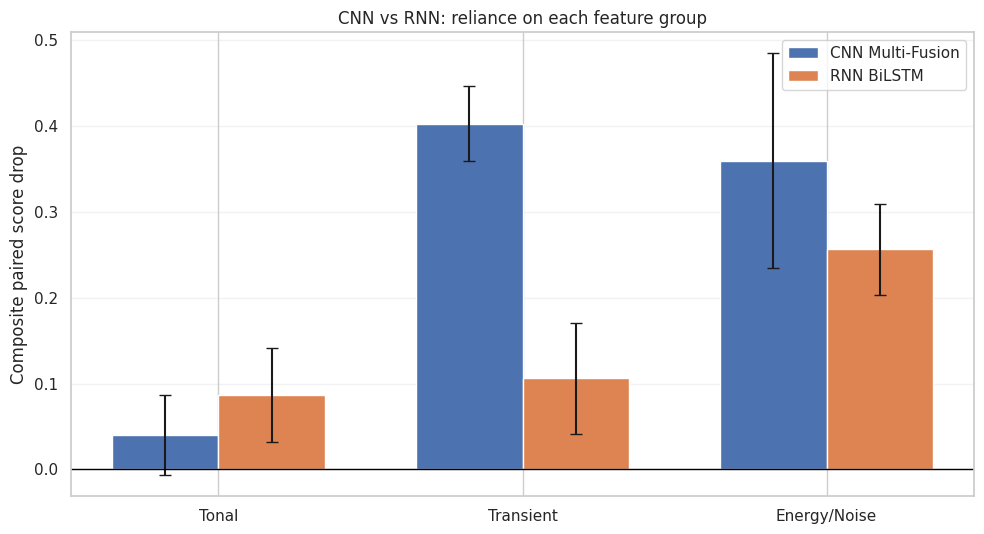

Cross-architecture tables and graphs saved in: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/branch_importance_results


In [21]:
# This cell becomes active after BOTH experiment notebooks have been run.
cnn_path = RESULTS_DIR / "cnn_multifusion_ablation_runs.csv"
rnn_path = RESULTS_DIR / "rnn_bilstm_ablation_runs.csv"

if not (cnn_path.exists() and rnn_path.exists()):
    missing = [str(path.name) for path in (cnn_path, rnn_path) if not path.exists()]
    print(
        "Cross-architecture comparison is not ready yet.\n"
        "Run the other notebook, then rerun this cell.\n"
        "Missing: " + ", ".join(missing)
    )
else:
    combined = pd.concat(
        [pd.read_csv(cnn_path), pd.read_csv(rnn_path)],
        ignore_index=True,
    )

    full_combined = combined[combined["condition"] == "Full model"]
    architecture_table = full_combined.groupby("architecture")[METRIC_COLUMNS].agg(
        mean_std_text
    )
    display(architecture_table)
    architecture_table.to_csv(
        RESULTS_DIR / "cnn_vs_rnn_full_model_mean_std.csv"
    )

    comparison_importance_rows = []
    for architecture, architecture_df in combined.groupby("architecture"):
        full = architecture_df[
            architecture_df["condition"] == "Full model"
        ].set_index("seed")
        for _, row in architecture_df[
            architecture_df["condition"] != "Full model"
        ].iterrows():
            base = full.loc[int(row["seed"])]
            item = {
                "architecture": architecture,
                "seed": int(row["seed"]),
                "group": row["masked_group"],
            }
            for metric in METRIC_COLUMNS:
                item[f"drop_{metric}"] = float(base[metric]) - float(row[metric])
            item["composite_drop"] = np.mean(
                [
                    item["drop_accuracy"],
                    item["drop_choking_f1"],
                    item["drop_laughter_f1"],
                ]
            )
            comparison_importance_rows.append(item)

    comparison_importance = pd.DataFrame(comparison_importance_rows)
    comparison_importance.to_csv(
        RESULTS_DIR / "cnn_vs_rnn_paired_importance_runs.csv",
        index=False,
    )

    comparison_summary = (
        comparison_importance.groupby(["architecture", "group"])[
            [f"drop_{metric}" for metric in METRIC_COLUMNS] + ["composite_drop"]
        ]
        .agg(["mean", "std"])
    )
    comparison_summary.columns = [
        f"{metric}_{stat}" for metric, stat in comparison_summary.columns
    ]
    display(comparison_summary.round(4))
    comparison_summary.to_csv(
        RESULTS_DIR / "cnn_vs_rnn_importance_summary.csv"
    )

    # Full-model comparison for every requested metric.
    architecture_order = list(full_combined["architecture"].drop_duplicates())
    plot_means = full_combined.groupby("architecture")[METRIC_COLUMNS].mean()
    plot_stds = full_combined.groupby("architecture")[METRIC_COLUMNS].std(ddof=1)
    x = np.arange(len(METRIC_COLUMNS))
    width = 0.35

    plt.figure(figsize=(15, 6))
    for arch_index, architecture in enumerate(architecture_order):
        offset = (arch_index - (len(architecture_order) - 1) / 2) * width
        plt.bar(
            x + offset,
            plot_means.loc[architecture, METRIC_COLUMNS],
            width,
            yerr=plot_stds.loc[architecture, METRIC_COLUMNS],
            capsize=3,
            label=architecture,
        )
    plt.xticks(
        x,
        ["Accuracy", "Choke P", "Choke R", "Choke F1",
         "Laugh P", "Laugh R", "Laugh F1"],
        rotation=20,
        ha="right",
    )
    plt.ylim(0, 1.05)
    plt.ylabel("Mean test score ± standard deviation")
    plt.title("CNN vs RNN: full-model performance across six seeded runs")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    comparison_plot_path = RESULTS_DIR / "cnn_vs_rnn_full_model_comparison.png"
    plt.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
    plt.show()

    # Composite group reliance comparison.
    composite = (
        comparison_importance.groupby(["architecture", "group"])["composite_drop"]
        .agg(["mean", "std"])
        .reset_index()
    )
    groups = list(FEATURE_GROUPS.keys())
    x = np.arange(len(groups))
    width = 0.35

    plt.figure(figsize=(10, 5.5))
    for arch_index, architecture in enumerate(architecture_order):
        subset = composite[composite["architecture"] == architecture].set_index("group")
        offset = (arch_index - (len(architecture_order) - 1) / 2) * width
        plt.bar(
            x + offset,
            subset.loc[groups, "mean"],
            width,
            yerr=subset.loc[groups, "std"],
            capsize=4,
            label=architecture,
        )
    plt.axhline(0, color="black", linewidth=1)
    plt.xticks(x, groups)
    plt.ylabel("Composite paired score drop")
    plt.title("CNN vs RNN: reliance on each feature group")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    importance_comparison_path = (
        RESULTS_DIR / "cnn_vs_rnn_group_importance_comparison.png"
    )
    plt.savefig(importance_comparison_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Cross-architecture tables and graphs saved in:", RESULTS_DIR)

## Interpretation guidance for the report

Report the mean and standard deviation across the six seeds. A group
is most convincingly important when masking it causes a positive
drop across several metrics and across most or all runs. Do not rank
groups from accuracy alone: choking recall is especially important
because it reflects missed choking cases, while the two class F1
scores summarize the precision–recall balance.

Precision and recall can move in opposite directions after masking.
For example, lower choking recall together with higher choking
precision means the model became more conservative about predicting
choking; this should not be described simply as an improvement.

The composite score averages the drops in accuracy, choking F1, and
laughter F1 and is included only as a convenient ranking aid. The
complete per-metric table and heatmap are the primary results.